# Optimization geometry and diagnostics: what a training curve cannot tell you

## 1. Introduction and learning objectives

A loss curve is an observation, not a diagnosis. Slow progress can arise from poorly scaled curvature, small transmitted sensitivities, a stationary saddle, stochastic variation, an oversized rate, or an incorrect derivative. Some mechanisms produce similar plots. A useful investigation states a hypothesis, checks the computation independently, measures the relevant quantities, and changes one factor under declared controls.

Derive local curvature and fixed-quadratic stability, implement exact manual Hessian–vector products, distinguish full Hessians from Gauss–Newton matrices, and verify small cases against an independent scalar objective. Quantify mini-batch variation at a fixed parameter snapshot, inspect activation and backward-sensitivity distributions, and run bounded initialization/rate interventions. Interpret every diagnostic with its assumptions; eigenvalues, gradient norms and finite seed panels do not automatically certify generalization or universal optimizer quality.

**Prerequisites:** Stage 00 matrix calculus, expectation/covariance, finite differences and numerical precision; Stage 01 generalization/evaluation; and Stage 04 [backpropagation](backpropagation.ipynb), [MLP](multilayer-perceptron.ipynb) and [optimizer state](momentum-and-adam.ipynb). Everything uses manual NumPy calculus. No framework/autodiff engine or earlier reference code is imported. Normalization/dropout and the learner-built reverse-mode engine remain subsequent units.

## 2. Prerequisites and mathematical foundations

Observations are rows $X:(n,d)$ and scalar regression targets are $y:(n,)$. Layer weights have shape $(d_{j-1},d_j)$; every bias is one-dimensional $(d_j,)$. For convenient directional calculations only, flatten each layer's row-major weight matrix **then** its bias vector, in forward layer order, into $\theta:(p,)$. Unpacking restores those shapes; no bias-gradient broadcasting is permitted.

Use a smooth tanh network with linear scalar output $f_\theta(x)$. The objective is
$$J(\theta)=\frac{1}{2n}\sum_i(f_\theta(x_i)-y_i)^2+\frac{\lambda}{2}\sum_j\|W_j\|_F^2.$$
It is half-MSE with weight-only L2. Let $r_i=f_i-y_i$, $g=\nabla_\theta J$ and $H=\nabla_\theta^2J$. The output sensitivity includes $1/n$ once; downstream products and bias sums do not average again. Targets, data, preprocessing, direction vectors and $\lambda$ are fixed when taking parameter derivatives.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 04.06.01 — Separate an observation, a mechanism and a claim

**Type:** Conceptual · **Answer:** Markdown

A run has flat loss and a tiny parameter-gradient norm. List at least three distinct possible explanations and one measurement/intervention for each. Which claims concern mathematical correctness, optimization, representation, statistical generalization or runtime? Explain why a held-out score or gradient check alone cannot identify all of them.

**Expected outcome:** a diagnostic argument with explicit alternatives and evidence, not a single label inferred from a curve.

**Your response to Exercise 04.06.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.01**

A constant predictor at a symmetric initialization can be stationary without minimizing the training objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.01**

A stationary saddle calls for directional curvature and a checked perturbation; saturation calls for activation derivatives and transmitted sensitivities; poor scaling calls for a curvature/coordinate probe; sampling noise calls for fixed-snapshot batch-gradient variation. A derivative bug requires independent objectives and finite differences before interpreting any of these. A constrained representation can have little useful progress even with correct optimization, while held-out deterioration raises separate sampling/selection/generalization questions. Runtime needs measured work and resources, not just update counts. These hypotheses can coexist. A low held-out score is predictive evidence under its sampling conditions; a local finite-difference check is implementation evidence at checked states, neither a complete diagnosis nor a global theorem.

</details>

## 3. Theoretical development and worked examples

### Curvature is local, directional and coordinate dependent

For a twice continuously differentiable objective,
$$J(\theta+s)=J(\theta)+g^Ts+\tfrac12s^THs+o(\|s\|^2).$$
A negative Rayleigh quotient $v^THv/\|v\|^2$ gives local negative curvature. At $g=0$ it rules out a local minimum. A positive-semidefinite Hessian at a stationary point is only a necessary second-order condition in general; zero-curvature directions can require higher orders. A positive-definite Hessian there is sufficient for a strict local minimum under these smoothness assumptions.

For the fixed quadratic $J(e)=e^TQe/2$, $Q=Q^T\succ0$, batch GD gives
$$e_t=(I-\eta Q)^te_0,\qquad e_{t,k}^{eig}=(1-\eta\lambda_k)^te_{0,k}^{eig}.$$
All modes contract exactly when $0<\eta<2/\lambda_{\max}$. The positive spectral condition number is $\kappa=\lambda_{\max}/\lambda_{\min}$; with the minimax constant rate $2/(\lambda_{\max}+\lambda_{\min})$, the worst factor is $(\kappa-1)/(\kappa+1)$. A large ratio can force a compromise between slow and oscillating modes. A local neural Hessian is generally changing and indefinite, so this fixed-quadratic bound cannot be promoted to a global neural rate guarantee.

If the gradient is $L$-Lipschitz along the whole update segment, the descent lemma bounds $J(\theta-\eta g)$ by $J(\theta)-\eta(1-L\eta/2)\|g\|^2$. Merely measuring one Hessian at the start does not verify such a segment-wide bound. Conditioning also changes with coordinates: under $\theta=S\phi$, $H_\phi=S^TH_\theta S$ for a fixed linear invertible $S$. The predictive function and the coordinate-dependent Euclidean gradient step are different objects.

### Exercise 04.06.02 — Derive quadratic contraction and restrict a descent statement

**Type:** Mathematical · **Answer:** Markdown

Derive the eigenmode recurrence, its strict stability interval, the minimax positive-definite quadratic rate and its worst contraction factor. Contrast the exact constant-Hessian setting with a changing neural Hessian and the segment-wide smoothness condition needed by the descent lemma.

**Expected outcome:** correct eigenvalue/rate factors, strict boundaries and a clear limit on neural-network conclusions.

**Your response to Exercise 04.06.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.02**

Balance the absolute factors of the smallest and largest eigenmodes; at the upper stability boundary a mode has multiplier $-1$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.02**

Diagonalize $Q=U\Lambda U^T$ and rotate the iterate to obtain independent multipliers $1-\eta\lambda_k$. Their absolute values are below one precisely on the strict interval. Balancing $1-\eta\lambda_{\min}=-(1-\eta\lambda_{\max})$ gives the stated minimax rate and factor. At $\eta=0$ there is no movement; at $2/\lambda_{\max}$ the largest mode need not decay. Integrating a Lipschitz-gradient bound on the update segment gives the descent lemma. A measured local spectrum does not establish that bound as the iterate moves, nor positive definiteness, correct stochastic directions, or successful nonconvex optimization.

</details>

### Exercise 04.06.03 — Predict rate behavior before plotting trajectories

**Type:** Numerical · **Answer:** Markdown

For eigenvalues $(1,25)$, calculate the strict GD stability bound, the minimax rate/factor, and the two mode multipliers at rates $.03,.07,.09$. Explain why an unstable algorithm might still appear stable if its initial vector lies exactly in a stable eigenspace.

**Expected outcome:** explicit mode arithmetic and an initialization-dependent limitation of a finite observed trajectory.

**Your response to Exercise 04.06.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.03**

The interval for all-mode contraction ends at $.08$; projecting away an unstable mode is a special initial condition, not all-mode stability.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.03**

The condition number is 25, the strict bound is $0<\eta<.08$, and the minimax rate is $2/26=1/13$ with worst factor $24/26=12/13$. At $.03$ the multipliers are $(.97,.25)$; at $.07$ they are $(.93,-.75)$; at $.09$ they are $(.91,-1.25)$. Thus the last rate amplifies any nonzero component in the largest-eigenvalue direction while alternating its sign. A finite run with zero such component can decay along the first direction; floating-point perturbations may later introduce the unstable component. All-mode stability is a statement about every initial error, not just one path.

</details>

### The full Hessian contains residual curvature

Let $a_i=\nabla_\theta f_i$ and let $M$ be a diagonal mask selecting weight coordinates. Differentiating the complete objective gives
$$H=\underbrace{\frac1n\sum_i a_i a_i^T+\lambda M}_{G\text{, Gauss--Newton plus penalty}}
 +\underbrace{\frac1n\sum_i r_i\nabla_\theta^2 f_i}_{\text{residual curvature}}.$$
$G$ is positive semidefinite for $\lambda\geq0$. The second term can be indefinite, and dropping it changes the matrix being analyzed. They coincide at zero residual, or for a prediction function linear in the complete parameter vector, but not for a general multilayer network. Positive semidefiniteness in output logits or least-squares residuals does not imply convexity in all network weights.

For a fixed direction $v$, define $R_v u(\theta)=\frac{d}{d\epsilon}u(\theta+\epsilon v)|_{\epsilon=0}$. Then $Hv=R_vg$ can be derived by applying product/chain rules to **manual backpropagation**, without storing a $p\times p$ matrix. For $A_0=X$, $Z_j=A_{j-1}W_j+b_j$, $A_j=\tanh Z_j$ on hidden layers:
$$RZ_j=(RA_{j-1})W_j+A_{j-1}V_{W_j}+V_{b_j},\quad
RA_j=(1-A_j^2)\odot RZ_j.$$
The output is linear. Let $D_j$ denote the loss sensitivity to $Z_j$, with $D_L=r_{:,None}/n$ and $RD_L=Rf_{:,None}/n$. Differentiate each weight/bias gradient:
$$R(\nabla_{W_j}J)=(RA_{j-1})^TD_j+A_{j-1}^TRD_j+\lambda V_{W_j},
\qquad R(\nabla_{b_j}J)=\sum_i(RD_j)_i.$$
For a hidden predecessor, write $U=D_jW_j^T$. Then
$$D_{j-1}=U\odot f'(Z_{j-1}),$$
$$RD_{j-1}=(RD_jW_j^T+D_jV_{W_j}^T)\odot f'(Z_{j-1})
+U\odot f''(Z_{j-1})\odot RZ_{j-1}.$$
Here $f'=\!1-\tanh^2z$ and $f''=-2\tanh z(1-\tanh^2z)$. Omitting the second-derivative term generally computes the wrong product. “Exact” means an analytic directional derivative implemented in floating point, not exact real arithmetic or a convergence proof.

### Exercise 04.06.04 — Derive the Hessian decomposition and directional reverse pass

**Type:** Mathematical · **Answer:** Markdown

Differentiate the half-MSE/weight-only-L2 objective twice, establish the Gauss–Newton quadratic form's nonnegativity, and derive the tangent-forward and tangent-backward rules. Explain how a $p$-vector product avoids the dense matrix and where the observation average appears.

**Expected outcome:** every product/chain-rule term, explicit shapes and a distinction between the full Hessian and its positive-semidefinite approximation.

**Your response to Exercise 04.06.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.04**

Differentiate $r_i a_i$ as $(Rr_i)a_i+r_i(Ra_i)$; these are the two curvature contributions.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.04**

Differentiating the gradient yields $a_i a_i^T+r_i\nabla^2f_i$ per row, averaged once, with $\lambda M$ from the penalty. Thus $v^TGv=n^{-1}\sum_i(a_i^Tv)^2+\lambda\|M v\|^2\geq0$ because the binary mask satisfies $M^TM=M$. Applying a directional derivative to the affine forward pass gives both weight and activation tangents plus bias tangent. Differentiating $A^TD$ gives the two matrix products, and differentiating $U f'$ adds $U f''RZ$ to the transformed upstream sensitivity. The output $D$ and $RD$ already contain $1/n$; averaging downstream again changes both gradient and curvature. The product stores layer-sized arrays and one parameter vector, whereas a dense Hessian needs quadratic parameter storage. This identity does not remove finite precision or the need for independent verification.

</details>

### Initialization arguments are approximate distribution calculations

For independent zero-mean weights with variance $\sigma_w^2$, independent input coordinates and appropriate finite moments, a preactivation sum has variance approximately $d_{in}\sigma_w^2E[A^2]$. Linear/near-zero tanh arguments motivate matching forward and backward scales; a compromise is $\sigma_w^2=2/(d_{in}+d_{out})$. The cited Glorot paper uses a uniform distribution; our experiment uses a normal distribution with the same variance, not identical samples.

For a symmetric preactivation $Z$, $E[\operatorname{ReLU}(Z)^2]=E[Z^2]/2$. The ReLU output has positive mean, so its **second moment is not its variance**. This motivates a hidden-layer variance $2/d_{in}$ under the idealized independence/symmetry calculation. A finite network trained on correlated inputs need not preserve either distribution across depth; initialization is not a guarantee of well-conditioned complete Jacobians. The linear output in our controlled profiles always uses variance $1/d_{in}$ for every nonzero preset.

### Exercise 04.06.05 — Distinguish activation variance, second moment and transmitted sensitivity

**Type:** Conceptual · **Answer:** Markdown

Why does using variance in place of the second moment give the wrong ReLU scaling argument? Distinguish a unit's activation derivative, the loss gradient to that unit, a weight gradient, and a vector–Jacobian probe supplied independently of the loss. Which quantities should be held fixed when comparing initialization mechanisms?

**Expected outcome:** the missing squared-mean term, separate derivative objects and controlled comparisons without an independence guarantee.

**Your response to Exercise 04.06.05**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.05**

The loss itself changes when the initialized model's predictions change; its output sensitivity is not automatically a common input probe.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.05**

$E[A^2]=\operatorname{Var}(A)+(E[A])^2$, and ReLU generally has a positive mean. A local activation derivative multiplies an upstream sensitivity, whose scale also reflects the rest of the network and, for a loss gradient, the prediction residual and reduction. Weight gradients additionally multiply incoming activations and sum over rows. A fixed independent output VJP probe isolates a declared Jacobian action from changing loss residuals; it does not sample all singular directions. Keep inputs, underlying random weight draws, widths, output scaling, probe and seeds fixed when changing hidden scales. Record both activation variance/second moment and transmitted sensitivities rather than inferring all behavior from one scalar initialization formula.

</details>

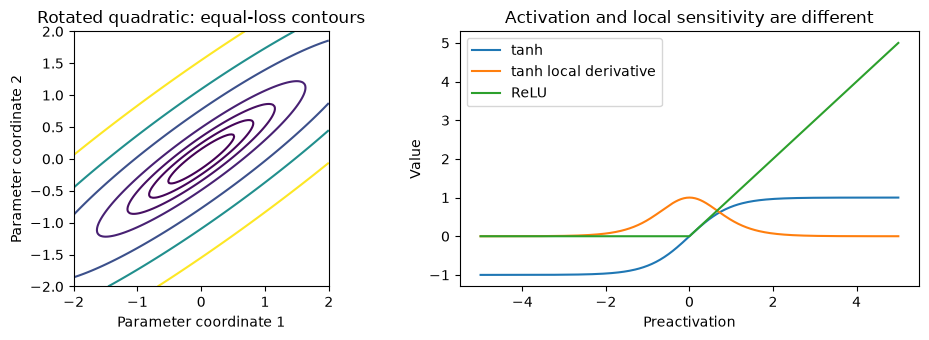

In [2]:
# Analytic curvature/activation views; no reference network or optimizer is defined.
grid_axis = np.linspace(-2, 2, 161)
gx, gy = np.meshgrid(grid_axis, grid_axis)
angle = np.pi / 5
u = np.cos(angle) * gx + np.sin(angle) * gy
v = -np.sin(angle) * gx + np.cos(angle) * gy
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].contour(gx, gy, .5 * (u**2 + 25*v**2), levels=[.2, .5, 1, 2, 5, 10, 20])
axes[0].set(xlabel="Parameter coordinate 1", ylabel="Parameter coordinate 2",
            title="Rotated quadratic: equal-loss contours", aspect="equal")
z = np.linspace(-5, 5, 301)
axes[1].plot(z, np.tanh(z), label="tanh")
axes[1].plot(z, 1-np.tanh(z)**2, label="tanh local derivative")
axes[1].plot(z, np.maximum(z, 0), label="ReLU")
axes[1].set(xlabel="Preactivation", ylabel="Value", title="Activation and local sensitivity are different")
axes[1].legend(); plt.tight_layout(); plt.show()

## 4. Guided exercises

### Exercise 04.06.06 — Implement manual gradients and analytic Hessian–vector products

**Type:** Programming · **Answer:** Code

Implement the declared flat-vector shape convention, bounded row-wise forward pass, manual half-MSE/L2 reverse pass and tangent of that reverse pass. Support tanh and linear hidden activations for curvature. ReLU uses a declared first derivative of zero at zero and is restricted to first-order diagnostics in this chapter. Return input gradients separately, keep all parameter snapshots unchanged and reject nonfinite preactivations before saturation can hide them.

**Expected outcome:** complete manual derivative rules without a dense Hessian, numerical differencing inside the algorithm, autodiff framework or learner-answer dependency.

In [ ]:
# Your code for Exercise 04.06.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.06**

Cache each incoming activation and its tangent. In reverse, save both old sensitivities before calculating their predecessors.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.06**

The block below supplies contracts and the complete reference computation used later. It caps 512 rows, 16 input features, widths 32, up to six hidden layers and 8,192 parameters. Weight-only penalties and a single output average apply throughout. ReLU curvature is deliberately rejected, even where a local piecewise derivative might be analyzed separately; zero is a first-order convention, not a classical derivative there. Inputs and returned parameter pieces use private copies.

~~~python
import copy
import itertools
import math
import time


def geo_integer(value, name, low, high):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or not low <= value <= high:
        raise ValueError(f"{name} must be an integer in [{low},{high}]")
    return int(value)


def geo_real(value, name, positive=False):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise ValueError(f"real scalar {name}")
    value = float(value)
    if not np.isfinite(value) or value < 0 or (positive and value == 0):
        raise ValueError(f"invalid {name}")
    return value


def geo_array(value, ndim):
    raw = np.asarray(value)
    if raw.dtype.kind not in "iuf" or raw.ndim != ndim:
        raise ValueError("real array with the declared dimensions")
    result = np.array(raw, dtype=float, copy=True)
    if not np.isfinite(result).all():
        raise ValueError("finite arrays required")
    return result


def geo_norm(value):
    result = math.hypot(*(float(v) for v in np.asarray(value).ravel()))
    if not np.isfinite(result):
        raise FloatingPointError("norm exceeds float64 range")
    return result


def geo_widths(widths):
    if not isinstance(widths, (tuple, list)) or not 2 <= len(widths) <= 8:
        raise ValueError("two to eight declared widths, including input/output")
    widths = tuple(geo_integer(w, "width", 1, 32) for w in widths)
    if widths[0] > 16 or widths[-1] != 1:
        raise ValueError("at most sixteen inputs and exactly one regression output")
    size = sum((a + 1) * b for a, b in zip(widths[:-1], widths[1:]))
    if size > 8192:
        raise ValueError("at most 8192 parameters in this chapter")
    return widths, size


def geo_unpack(theta, widths):
    widths, size = geo_widths(widths)
    theta = geo_array(theta, 1)
    if theta.shape != (size,):
        raise ValueError("parameter vector size does not match widths")
    pairs, cursor = [], 0
    for a, b in zip(widths[:-1], widths[1:]):
        end = cursor + a * b
        pairs.append((theta[cursor:end].reshape(a, b).copy(), theta[end:end + b].copy()))
        cursor = end + b
    return pairs


def geo_pack(pairs):
    return np.concatenate([piece.ravel() for pair in pairs for piece in pair])


def geo_forward(theta, X, widths, activation="tanh", direction=None):
    widths, _ = geo_widths(widths)
    pairs = geo_unpack(theta, widths)
    X = geo_array(X, 2)
    if not 1 <= len(X) <= 512 or X.shape[1] != widths[0]:
        raise ValueError("bounded nonempty row-wise input matrix")
    if activation not in ("tanh", "relu", "linear"):
        raise ValueError("activation")
    if direction is not None and activation == "relu":
        raise ValueError("this chapter derives smooth Hessian products; ReLU uses first-order probes only")
    tangent_pairs = geo_unpack(direction, widths) if direction is not None else [(np.zeros_like(w), np.zeros_like(b)) for w, b in pairs]
    A, Z, first, second = [X], [], [], []
    RA, RZ = [np.zeros_like(X)], []
    with np.errstate(over="raise", invalid="raise"):
        for layer, ((W, b), (VW, Vb)) in enumerate(zip(pairs, tangent_pairs)):
            z = A[-1] @ W + b
            rz = RA[-1] @ W + A[-1] @ VW + Vb
            if not np.isfinite(z).all() or not np.isfinite(rz).all():
                raise FloatingPointError("nonfinite preactivation or tangent")
            if layer == len(pairs) - 1 or activation == "linear":
                a, d1, d2 = z.copy(), np.ones_like(z), np.zeros_like(z)
            elif activation == "tanh":
                a = np.tanh(z); d1 = 1 - a ** 2; d2 = -2 * a * d1
            else:
                a = np.maximum(z, 0.); d1 = (z > 0).astype(float); d2 = np.zeros_like(z)
            A.append(a); Z.append(z); first.append(d1); second.append(d2)
            RA.append(d1 * rz); RZ.append(rz)
    return dict(pairs=pairs, tangent_pairs=tangent_pairs, A=A, Z=Z,
                first=first, second=second, RA=RA, RZ=RZ)


def geo_network(theta, X, y, widths, activation="tanh", l2=0., direction=None):
    y, l2 = geo_array(y, 1), geo_real(l2, "L2 coefficient")
    cache = geo_forward(theta, X, widths, activation, direction)
    if y.shape != (len(cache["A"][0]),):
        raise ValueError("one scalar target per row")
    n = len(y); prediction = cache["A"][-1][:, 0]
    with np.errstate(over="raise", invalid="raise"):
        residual = prediction - y
        loss = float(np.mean(residual ** 2) / 2)
        if l2:
            loss += l2 * sum(float(np.sum(w ** 2)) for w, _ in cache["pairs"]) / 2
        D, RD = residual[:, None] / n, cache["RA"][-1] / n
        gradients, products, sensitivities = [], [], []
        for j in range(len(cache["pairs"]) - 1, -1, -1):
            W, b = cache["pairs"][j]; VW, Vb = cache["tangent_pairs"][j]
            old_D, old_RD = D, RD
            gw = cache["A"][j].T @ old_D
            hw = cache["RA"][j].T @ old_D + cache["A"][j].T @ old_RD
            if l2:
                gw = gw + l2 * W; hw = hw + l2 * VW
            gradients.append((gw, old_D.sum(axis=0)))
            products.append((hw, old_RD.sum(axis=0)))
            sensitivities.append(old_D.copy())
            if j:
                upstream = old_D @ W.T
                D = upstream * cache["first"][j - 1]
                RD = (old_RD @ W.T + old_D @ VW.T) * cache["first"][j - 1] + upstream * cache["second"][j - 1] * cache["RZ"][j - 1]
        input_gradient = D @ cache["pairs"][0][0].T
    gradient, hvp = geo_pack(gradients[::-1]), geo_pack(products[::-1])
    if not np.isfinite(loss) or not np.isfinite(gradient).all() or not np.isfinite(hvp).all() or not np.isfinite(input_gradient).all():
        raise FloatingPointError("nonfinite objective or derivative")
    return dict(loss=loss, gradient=gradient, hvp=hvp if direction is not None else None,
                prediction=prediction, prediction_tangent=cache["RA"][-1][:, 0] if direction is not None else None,
                input_gradient=input_gradient, sensitivities=sensitivities[::-1], cache=cache)
~~~

</details>

### Exercise 04.06.07 — Independently audit curvature before computing spectra

**Type:** Programming · **Answer:** Code

Write a scalar-loop tanh objective that does not call vector forward, unpack or gradient helpers. Check every parameter gradient by central differences and each coordinate of $Hv$ using four scalar objective evaluations at $\theta\pm h e_j\pm h v$. State tolerances and inspect step-size sensitivity. Only for small problems, form dense Hessian columns from analytic products and output-Jacobian columns from forward tangents; record asymmetry before any symmetric eigensolver convention.

**Expected outcome:** independent objective evidence, explicit finite-difference limits and correct complete/Gauss–Newton matrices.

In [ ]:
# Your code for Exercise 04.06.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.07**

The four-point mixed difference divides by $4h^2$; it is a check with truncation/cancellation error, not the analytic product implementation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.07**

Depends on Exercise 04.06.06. The independent scalar objective has its own list-based parameter traversal and math.tanh evaluation. The fixture uses a unit-norm fixed direction, $h=10^{-4}$, gradient tolerance $10^{-6}$ and product tolerance $10^{-6}$. These absolute tolerances concern this moderate-scale fixture, not arbitrary parameter magnitudes. Dense inspection is limited to 128 parameters/64 rows; asymmetry outside a declared relative threshold is an error, not silently symmetrized away. The symmetric part is used only after reporting the raw error.

~~~python
def geo_scalar_objective(theta, X, y, widths, l2=0.):
    """Independent list/Python-math objective, with no vector forward or unpack."""
    pairs, cursor = [], 0
    for a, b in zip(widths[:-1], widths[1:]):
        weights = [[float(theta[cursor + i * b + j]) for j in range(b)] for i in range(a)]
        cursor += a * b
        bias = [float(v) for v in theta[cursor:cursor + b]]; cursor += b
        pairs.append((weights, bias))
    total = 0.
    for row, target in zip(X, y):
        values = [float(v) for v in row]
        for layer, (weights, bias) in enumerate(pairs):
            values = [sum(v * weights[i][j] for i, v in enumerate(values)) + bias[j] for j in range(len(bias))]
            if layer != len(pairs) - 1:
                values = [math.tanh(v) for v in values]
        total += (values[0] - float(target)) ** 2 / (2 * len(y))
    return total + l2 * sum(v * v for weights, _ in pairs for row in weights for v in row) / 2


def geo_audit(theta, X, y, widths, direction, l2=.02, delta=1e-4):
    theta, direction = geo_array(theta, 1), geo_array(direction, 1)
    delta = geo_real(delta, "difference step", positive=True)
    if theta.shape != direction.shape or len(theta) > 128:
        raise ValueError("small equal-length parameter/direction vectors")
    actual = geo_network(theta, X, y, widths, l2=l2, direction=direction)
    independent_gradient = np.empty_like(theta)
    independent_product = np.empty_like(theta)
    for j in range(len(theta)):
        e = np.zeros_like(theta); e[j] = delta
        independent_gradient[j] = (geo_scalar_objective(theta + e, X, y, widths, l2) - geo_scalar_objective(theta - e, X, y, widths, l2)) / (2 * delta)
        independent_product[j] = (geo_scalar_objective(theta + e + delta * direction, X, y, widths, l2)
                                  - geo_scalar_objective(theta + e - delta * direction, X, y, widths, l2)
                                  - geo_scalar_objective(theta - e + delta * direction, X, y, widths, l2)
                                  + geo_scalar_objective(theta - e - delta * direction, X, y, widths, l2)) / (4 * delta ** 2)
    return dict(loss_error=abs(actual["loss"] - geo_scalar_objective(theta, X, y, widths, l2)),
                gradient_error=float(np.max(abs(actual["gradient"] - independent_gradient))),
                hvp_error=float(np.max(abs(actual["hvp"] - independent_product))))


def geo_curvature(theta, X, y, widths, l2=0.):
    theta = geo_array(theta, 1)
    if len(theta) > 128 or not 1 <= len(X) <= 64:
        raise ValueError("dense curvature is restricted to at most 128 parameters and 64 rows")
    columns = [geo_network(theta, X, y, widths, l2=l2, direction=v) for v in np.eye(len(theta))]
    H = np.column_stack([r["hvp"] for r in columns])
    jacobian = np.column_stack([r["prediction_tangent"] for r in columns])
    mask = geo_pack([(np.ones_like(w), np.zeros_like(b)) for w, b in columns[0]["cache"]["pairs"]])
    G = jacobian.T @ jacobian / len(X) + l2 * np.diag(mask)
    asymmetry = float(np.max(abs(H - H.T)))
    if asymmetry > 1e-10 * max(1., float(np.max(abs(H)))):
        raise ArithmeticError("unexpected Hessian asymmetry; inspect before symmetrizing")
    return dict(hessian=H, gauss_newton=G, residual_curvature=H - G,
                jacobian=jacobian, asymmetry=asymmetry,
                eigenvalues=np.linalg.eigvalsh((H + H.T) / 2),
                gauss_newton_eigenvalues=np.linalg.eigvalsh(G))
curvature_widths = (2, 3, 1)
curvature_theta = np.linspace(-.3, .4, 13)
curvature_x = np.array([[-.7,.2],[.3,-.5],[.8,.4]])
curvature_y = np.array([.4,-.2,.7])
curvature_direction = np.random.default_rng(40602).normal(size=13)
curvature_direction /= np.linalg.norm(curvature_direction)
for difference_step in (1e-2, 1e-4, 1e-6):
    curvature_check = geo_audit(curvature_theta, curvature_x, curvature_y, curvature_widths,
                                curvature_direction, delta=difference_step)
    print("Independent scalar audit, step/error:", difference_step, curvature_check)
    if difference_step == 1e-4:
        assert curvature_check["loss_error"] < 1e-12
        assert curvature_check["gradient_error"] < 1e-6 and curvature_check["hvp_error"] < 1e-6
~~~

</details>

### Exercise 04.06.08 — Verify an exactly stationary saddle by hand

**Type:** Mathematical · **Answer:** Markdown

Take two rows $x=(-1,1)$, targets $y=(-1,1)$, and $f(x)=v\tanh(wx+b)+c$ at $(w,b,v,c)=0$, with no penalty. Compute the loss, full gradient, Hessian, Gauss–Newton matrix and spectra. Exhibit a negative-curvature direction and check that a small finite perturbation lowers loss.

**Expected outcome:** a zero gradient with a non-minimum certificate and an explicit matrix in the declared coordinate order.

**Your response to Exercise 04.06.08**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.08**

At zero, only the output-bias Jacobian is nonzero; the residual couples the two weight coordinates in the full second derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.08**

The loss is $1/2$ and the gradient is the zero vector. In order $(w,b,v,c)$,
$$H=\begin{pmatrix}0&0&-1&0\\0&0&0&0\\-1&0&0&0\\0&0&0&1\end{pmatrix},
\qquad G=\operatorname{diag}(0,0,0,1).$$
The spectra are $(-1,0,1,1)$ and $(0,0,0,1)$. Direction $(1,0,1,0)/\sqrt2$ has Rayleigh quotient $-1$. Taking equal small nonzero $w=v=a$, zero biases, gives predictions $\pm a\tanh a$, so the loss is $(1-a\tanh a)^2/2<1/2$ for sufficiently small $a$. The origin is stationary but not a local minimum. Positive-semidefinite Gauss–Newton inspection alone would miss this negative residual curvature. The next experiments check the analytic implementation against these hand matrices.

</details>

### Exercise 04.06.09 — Show why a raw sharpness number needs coordinates

**Type:** Numerical · **Answer:** Markdown

Consider a two-weight scalar linear model $f(x)=abx$, trained on $x=y=1$, with loss $(ab-1)^2/2$ and no penalty. At $(a,b)=(s,1/s)$, derive the two-weight Hessian and its nonzero eigenvalue. Compare $s=1$ and $s=10$. Does a larger value by itself mean worse predictions or generalization?

**Expected outcome:** identical functions/losses with different coordinate curvature, and a limit on an unqualified sharpness claim.

**Your response to Exercise 04.06.09**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.09**

At exact fit, the Hessian is the outer product of the prediction gradient $(b,a)$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.09**

The matrix is $\begin{pmatrix}s^{-2}&1\\1&s^2\end{pmatrix}$, with eigenvalues zero and $s^2+s^{-2}$. The nonzero eigenvalue is 2 at $s=1$ and 100.01 at $s=10$, while $ab=1$ and the predictive function is $f(x)=x$ for every $x$ in both cases. No predictive difference follows from this raw number. This is a restricted two-weight example without bias or regularization, not a claim that every model is freely rescalable or that all curvature notions are useless. Specify parameterization, normalization, objective and perturbation metric before interpreting sharpness.

</details>

## 5. Implementation challenges

### Exercise 04.06.10 — Implement paired initialization and an independent output probe

**Type:** Programming · **Answer:** Code

Implement zero, small, fan-in, Glorot-variance, He-variance and large hidden-weight scales using the same underlying standard-normal draws for each paired seed. Use zero biases and fixed fan-in scaling at the linear output for every nonzero preset. Backpropagate a separately supplied output probe without a loss reduction; record activation means, population variances, second moments, derivative RMS, low-derivative fractions and preactivation-sensitivity RMS per layer. Return the input VJP.

**Expected outcome:** declared scale/shape conventions and diagnostics that distinguish local derivatives, loss-dependent gradients and a fixed Jacobian probe.

In [ ]:
# Your code for Exercise 04.06.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.10**

The probe is a vector in output space; its VJP is not the full Jacobian or all its singular values. Record the linear output separately from hidden activations.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.10**

Depends on Exercise 04.06.06. The normal scales for hidden weights are $0$, $.03/\sqrt{d_{in}}$, $1/\sqrt{d_{in}}$, $\sqrt{2/(d_{in}+d_{out})}$, $\sqrt{2/d_{in}}$, and $3/\sqrt{d_{in}}$. The linear output uses $1/\sqrt{d_{in}}$ except for the all-zero preset. Reusing the seed gives the same base matrices across scales, not equal initialized parameter values. Variance uses ddof=0 across the finite batch/unit panel. A fraction below derivative $.01$ describes this finite probe; it is not a count of permanently dead units or a theorem about an entire data distribution.

~~~python
def geo_initialize(widths, seed=40601, scheme="glorot"):
    widths, _ = geo_widths(widths)
    seed = geo_integer(seed, "initialization seed", 0, 2**32 - 1)
    if scheme not in ("zero", "small", "fan_in", "glorot", "he", "large"):
        raise ValueError("initialization scheme")
    rng = np.random.default_rng(seed); pairs = []
    for layer, (a, b) in enumerate(zip(widths[:-1], widths[1:])):
        base = rng.normal(size=(a, b))
        if layer == len(widths) - 2 and scheme != "zero":
            scale = math.sqrt(1 / a)  # Same linear output scaling across all nonzero presets.
        else:
            scale = {"zero": 0., "small": .03 / math.sqrt(a), "fan_in": math.sqrt(1 / a),
                     "glorot": math.sqrt(2 / (a + b)), "he": math.sqrt(2 / a), "large": 3 / math.sqrt(a)}[scheme]
        pairs.append((scale * base, np.zeros(b)))
    return geo_pack(pairs)


def geo_transmission(theta, X, widths, activation, probe):
    cache = geo_forward(theta, X, widths, activation)
    D = geo_array(probe, 2)
    if D.shape != cache["A"][-1].shape:
        raise ValueError("one upstream sensitivity per output; no loss normalization in this probe")
    layers = []
    with np.errstate(over="raise", invalid="raise"):
        for j in range(len(cache["pairs"]) - 1, -1, -1):
            layers.append(dict(layer=j, activation_mean=float(np.mean(cache["A"][j + 1])),
                               activation_variance=float(np.var(cache["A"][j + 1], ddof=0)),
                               activation_second_moment=float(np.mean(cache["A"][j + 1] ** 2)),
                               derivative_rms=float(np.sqrt(np.mean(cache["first"][j] ** 2))),
                               low_derivative_fraction=float(np.mean(cache["first"][j] < .01)),
                               sensitivity_rms=float(np.sqrt(np.mean(D ** 2)))))
            D = D @ cache["pairs"][j][0].T
            if j:
                D = D * cache["first"][j - 1]
    if not np.isfinite(D).all() or any(not np.isfinite(v) for row in layers for v in row.values()):
        raise FloatingPointError("nonfinite transmission diagnostic")
    return dict(layers=layers[::-1], input_vjp=D,
                input_rms=float(np.sqrt(np.mean(D ** 2))),
                upstream_rms=float(np.sqrt(np.mean(np.asarray(probe) ** 2))))
~~~

</details>

### Fixed-snapshot gradient variation

Let $g_i$ be the per-row gradient at the **same** parameter vector, including the same deterministic penalty gradient if desired. Define $\bar g=n^{-1}\sum_i g_i$ and the finite-row population covariance
$$S=\frac1n\sum_i(g_i-\bar g)(g_i-\bar g)^T.$$
For a mean over $b$ independent uniform draws with replacement, $E[\hat g]=\bar g$ and $\operatorname{Cov}(\hat g)=S/b$. For a uniformly chosen size-$b$ subset without replacement at this fixed snapshot,
$$\operatorname{Cov}(\hat g)=\frac{n-b}{b(n-1)}S.$$
The covariance convention is ddof=0; substituting the usual ddof=1 sample covariance changes the factor. Sampling without replacement across a changing-parameter epoch is a different conditional process. Neither formula alone says that a stochastic optimizer update is unbiased after clipping/adaptation or that equal update counts consume equal examples.

### Exercise 04.06.11 — Enumerate small batches and verify the covariance law

**Type:** Programming · **Answer:** Code

Implement explicit per-row manual gradients on a small frozen dataset. Enumerate all ordered with-replacement batches or all unordered without-replacement subsets under uniform sampling; cap the enumeration size. Compute their mean/covariance directly and compare with the appropriate finite-population formula. Verify that a shared L2 gradient changes the mean but not covariance.

**Expected outcome:** exact finite enumeration, explicit covariance denominators, retained batch means and a fixed-snapshot scope.

In [ ]:
# Your code for Exercise 04.06.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.11**

For $n=8,b=4$, there are $8^4=4096$ ordered replacement batches and $\binom84=70$ subsets; every enumerated case has equal weight in its own experiment.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.11**

Depends on Exercise 04.06.06. Per-row gradients use one-row half-MSE, so their mean recovers the full mean gradient; a once-added deterministic L2 term can be included in each and averaged, rather than summed repeatedly. Explicit matrices are restricted to 64 rows/128 parameters; enumeration accepts 2–12 rows, batches up to 4, 128 coordinates and at most 5,000 cases. The covariance is of the enumerated finite population, not a statistical covariance estimate requiring ddof=1. No Monte Carlo agreement or asymptotic approximation is needed for this bounded identity.

~~~python
def geo_row_gradients(theta, X, y, widths, l2=0.):
    if not 1 <= len(X) <= 64 or len(theta) > 128:
        raise ValueError("small explicit per-row gradients only")
    return np.array([geo_network(theta, X[i:i + 1], y[i:i + 1], widths, l2=l2)["gradient"] for i in range(len(X))])


def geo_exact_batch_panel(rows, batch=2, replacement=True):
    rows = geo_array(rows, 2)
    if not 2 <= len(rows) <= 12 or not 1 <= rows.shape[1] <= 128:
        raise ValueError("two to twelve finite row gradients, at most 128 coordinates")
    batch = geo_integer(batch, "batch size", 1, min(4, len(rows)))
    if type(replacement) is not bool:
        raise ValueError("declare replacement as a boolean")
    count = len(rows) ** batch if replacement else math.comb(len(rows), batch)
    if count > 5000:
        raise ValueError("enumeration exceeds 5000 batches")
    indices = itertools.product(range(len(rows)), repeat=batch) if replacement else itertools.combinations(range(len(rows)), batch)
    with np.errstate(over="raise", invalid="raise"):
        means = np.array([rows[list(index)].mean(axis=0) for index in indices])
        mean = rows.mean(axis=0); centered = rows - mean
        empirical = centered.T @ centered / len(rows)  # Population covariance of the fixed finite row set.
        multiplier = 1 / batch if replacement else (len(rows) - batch) / (batch * (len(rows) - 1))
        centered_means = means - means.mean(axis=0)
        covariance = centered_means.T @ centered_means / len(means)
    if not np.isfinite(covariance).all() or not np.isfinite(empirical).all():
        raise FloatingPointError("finite-population covariance exceeds float64 range")
    return dict(mean=mean, batch_means=means, covariance=covariance,
                expected_covariance=multiplier * empirical, count=count,
                maximum_error=float(np.max(abs(covariance - multiplier * empirical))))
~~~

</details>

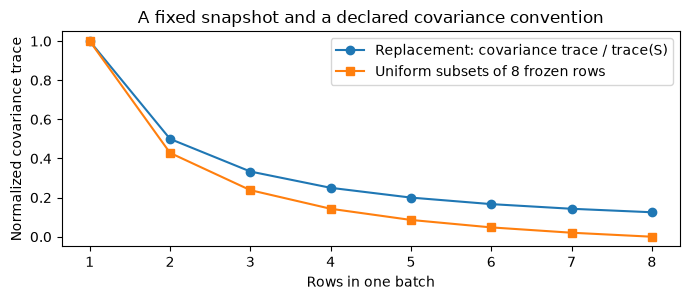

In [3]:
# A prescribed finite covariance illustrates denominators; no batch-enumeration helper.
batch_axis = np.arange(1, 9)
fig, ax = plt.subplots(figsize=(7, 3.1))
ax.plot(batch_axis, 1/batch_axis, "o-", label="Replacement: covariance trace / trace(S)")
ax.plot(batch_axis, (8-batch_axis)/(7*batch_axis), "s-", label="Uniform subsets of 8 frozen rows")
ax.set(xlabel="Rows in one batch", ylabel="Normalized covariance trace",
       title="A fixed snapshot and a declared covariance convention")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Experiments and visualizations

### Exercise 04.06.12 — Match quadratic paths to their spectra

**Type:** Experimental · **Answer:** Code

Rotate a quadratic with eigenvalues $(1,25)$ by $\pi/5$ and start at $(2,-1)$. Run 80 GD updates at $.03,.07,.09$. Keep every state/loss. Plot stable paths on fixed contours and all three losses against updates, explicitly showing the unstable rate's outcome. Check against the independent eigenbasis recurrence, and state why this is an exact quadratic investigation rather than a neural learning-rate theorem.

**Expected outcome:** declared rates/budget, complete trajectories and a plot whose viewport does not silently hide the unstable outcome.

In [ ]:
# Your code for Exercise 04.06.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.12**

Use the same initial vector and matrix at every rate. A contour window can show the stable paths while the separate loss panel retains the expanding path.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.12**

Depends only on the contracts from Exercise 04.06.06. The supplied matrix is built symmetric from two orthogonal eigenvectors; the helper accepts a small numerical symmetry tolerance. The reference left panel deliberately shows **stable paths only**, with the expanding case retained in the right panel and complete arrays. Zero/negative eigenvalues fall outside this helper's positive-definite claim. The scalar mode formula, not another call to GD, is an independent trajectory oracle in the tests.

~~~python
def geo_quadratic(Q, initial, rate=.03, steps=80):
    Q, initial = geo_array(Q, 2), geo_array(initial, 1)
    rate, steps = geo_real(rate, "rate", positive=True), geo_integer(steps, "steps", 1, 1000)
    if not 1 <= len(initial) <= 16 or Q.shape != (len(initial), len(initial)) or not np.allclose(Q, Q.T, atol=1e-13, rtol=0):
        raise ValueError("small symmetric quadratic matrix")
    eigenvalues = np.linalg.eigvalsh(Q)
    if eigenvalues[0] <= 0:
        raise ValueError("the stated stability analysis needs a positive-definite quadratic")
    states = [initial.copy()]
    with np.errstate(over="raise", invalid="raise"):
        for _ in range(steps):
            states.append(states[-1] - rate * (Q @ states[-1]))
        states = np.array(states)
        losses = np.einsum("ni,ij,nj->n", states, Q, states) / 2
    if not np.isfinite(losses).all():
        raise FloatingPointError("quadratic trajectory exceeds float64 range")
    return dict(states=states, losses=losses, eigenvalues=eigenvalues,
                stable_rate=bool(0 < rate < 2 / eigenvalues[-1]))
quadratic_angle = np.pi/5
quadratic_rotation = np.array([[np.cos(quadratic_angle), -np.sin(quadratic_angle)],
                               [np.sin(quadratic_angle), np.cos(quadratic_angle)]])
quadratic_matrix = quadratic_rotation @ np.diag([1.,25.]) @ quadratic_rotation.T
quadratic_paths = {rate:geo_quadratic(quadratic_matrix,[2.,-1.],rate,80) for rate in (.03,.07,.09)}
fig, axes = plt.subplots(1,2,figsize=(10.5,3.6))
qx,qy = np.meshgrid(np.linspace(-2.5,2.5,161),np.linspace(-2.5,2.5,161))
qpoints = np.stack((qx,qy),axis=-1)
qvalues = np.einsum("...i,ij,...j->...",qpoints,quadratic_matrix,qpoints)/2
axes[0].contour(qx,qy,qvalues,levels=[.2,.5,1,2,5,10,20],colors="gray",alpha=.45)
for rate,result in quadratic_paths.items():
    print("Quadratic rate / eigenvalues / all-mode stability / last loss:",
          rate,result["eigenvalues"],result["stable_rate"],result["losses"][-1])
    if result["stable_rate"]:
        axes[0].plot(result["states"][:,0],result["states"][:,1],".-",label=f"rate={rate}")
    axes[1].semilogy(result["losses"],label=f"rate={rate}, stable={result['stable_rate']}")
axes[0].set(xlabel="Coordinate 1",ylabel="Coordinate 2",aspect="equal",
            title="Stable trajectories only; all outcomes at right",xlim=(-2.5,2.5),ylim=(-2.5,2.5))
axes[1].set(xlabel="Committed updates",ylabel="Quadratic loss",title="Same start and 80 updates, including unstable rate")
for ax in axes: ax.legend()
plt.tight_layout();plt.show()
~~~

</details>

### Exercise 04.06.13 — Check full and approximate curvature at the stationary saddle

**Type:** Experimental · **Answer:** Code

Compute the analytic products, dense small Hessian, Gauss–Newton matrix and a loss slice for the hand saddle in Exercise 04.06.08. Compare matrices/spectra to the explicit values. Repeat with targets equal to a fixed nonzero network's predictions and verify the zero-residual equality, keeping targets fixed during differentiation. Record symmetry error and finite-difference evidence.

**Expected outcome:** an exact non-minimum certificate, a retained negative residual-curvature contribution and a correctly scoped zero-residual comparison.

In [ ]:
# Your code for Exercise 04.06.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.13**

Freezing targets to current predictions defines a new fixed dataset. Recomputing those targets after each parameter perturbation would differentiate a different objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.13**

Depends on Exercises 04.06.06–07. The first fixture gives a zero gradient and the printed negative eigenvalue, while the PSD approximation lacks that direction. The independent scalar four-point audit checks products at this fixture too. In the second fixture the targets are copied once; residual curvature vanishes at that snapshot, including the same weight-only penalty in both matrices. It is not asserted to vanish after a training move. A dense spectrum is for these tiny cases only.

~~~python
saddle_widths=(1,1,1);saddle_theta=np.zeros(4)
saddle_x=np.array([[-1.],[1.]]);saddle_y=np.array([-1.,1.])
saddle_state=geo_network(saddle_theta,saddle_x,saddle_y,saddle_widths)
saddle_curvature=geo_curvature(saddle_theta,saddle_x,saddle_y,saddle_widths)
saddle_direction=np.array([1.,0.,1.,0.])/np.sqrt(2)
print("Saddle loss / gradient / full spectrum / GN spectrum:",
      saddle_state["loss"],saddle_state["gradient"],saddle_curvature["eigenvalues"],
      saddle_curvature["gauss_newton_eigenvalues"])
print("Saddle independent check:",geo_audit(saddle_theta,saddle_x,saddle_y,saddle_widths,saddle_direction,l2=0.))
assert np.allclose(saddle_curvature["eigenvalues"],[-1.,0.,1.,1.])
fit_targets=geo_network(curvature_theta,curvature_x,np.zeros(3),curvature_widths)["prediction"].copy()
zero_residual=geo_curvature(curvature_theta,curvature_x,fit_targets,curvature_widths,l2=.02)
print("Zero-residual H-G maximum difference / raw asymmetry:",
      abs(zero_residual["residual_curvature"]).max(),zero_residual["asymmetry"])
assert abs(zero_residual["residual_curvature"]).max()<1e-12
saddle_steps=np.linspace(-1.5,1.5,161)
saddle_slice=[geo_scalar_objective(saddle_theta+s*saddle_direction,saddle_x,saddle_y,saddle_widths) for s in saddle_steps]
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
axes[0].plot(saddle_steps,saddle_slice);axes[0].axvline(0,color="gray",linestyle="--")
axes[0].set(xlabel="Signed displacement along negative-curvature direction",ylabel="Half-MSE",
            title="Zero gradient at the origin does not imply a minimum")
axes[1].plot(saddle_curvature["eigenvalues"],"o-",label="Full Hessian")
axes[1].plot(saddle_curvature["gauss_newton_eigenvalues"],"s--",label="Gauss–Newton")
axes[1].axhline(0,color="gray");axes[1].legend()
axes[1].set(xlabel="Sorted eigenvalue index",ylabel="Eigenvalue",title="PSD approximation omits residual curvature")
plt.tight_layout();plt.show()
~~~

</details>

### Exercise 04.06.14 — Verify batch-noise laws and an unbiasedness failure

**Type:** Experimental · **Answer:** Code

At one frozen 13-parameter tanh network, generate eight deterministic rows and compute their per-row gradients. Enumerate batch sizes 1, 2 and 4 both with and without replacement. Compare all means/covariances, and plot covariance traces with their declared theoretical values. Separately use scalar gradients $(-4,2,2)$ to show that clipping each to norm 1 changes a zero mean to a nonzero mean.

**Expected outcome:** exact finite-population identities with explicit units, and a counterexample to unrestricted clipping-unbiasedness claims.

In [ ]:
# Your code for Exercise 04.06.14.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.14**

The clipping counterexample is a prescribed finite gradient distribution, not a claim that those values came from the tanh dataset.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.14**

Depends on Exercises 04.06.06 and 11. All covariance calculations freeze the model and training rows, with ddof=0. Adding the same penalty gradient to all rows cancels under centering. The separate three-value distribution has mean zero, but clipped values $(-1,1,1)$ have mean $1/3$. No Adam or training convergence claim follows from the covariance identity, and a uniform-subset result does not certify a changing-parameter epoch process.

~~~python
noise_rng=np.random.default_rng(40604)
noise_x=noise_rng.normal(size=(8,2));noise_y=np.sin(noise_x[:,0])+.1*noise_x[:,1]
noise_rows=geo_row_gradients(curvature_theta,noise_x,noise_y,curvature_widths,l2=.02)
noise_full=geo_network(curvature_theta,noise_x,noise_y,curvature_widths,l2=.02)
assert np.allclose(noise_rows.mean(axis=0),noise_full["gradient"],atol=1e-13)
noise_panels={}
for replacement in (True,False):
    for batch in (1,2,4):
        panel=geo_exact_batch_panel(noise_rows,batch,replacement)
        noise_panels[(replacement,batch)]=panel
        print("Replacement / batch / enumerated count / covariance max error:",
              replacement,batch,panel["count"],panel["maximum_error"])
        assert panel["maximum_error"]<1e-12
prescribed=np.array([-4.,2.,2.]);clipped=np.clip(prescribed,-1.,1.)
print("Prescribed / clipped scalar means:",prescribed.mean(),clipped.mean())
fig,ax=plt.subplots(figsize=(7.5,3.3))
for replacement,label in ((True,"replacement"),(False,"uniform subsets")):
    empirical=[np.trace(noise_panels[(replacement,b)]["covariance"]) for b in (1,2,4)]
    predicted=[np.trace(noise_panels[(replacement,b)]["expected_covariance"]) for b in (1,2,4)]
    line,=ax.plot([1,2,4],predicted,"-",label=f"{label}, formula")
    ax.scatter([1,2,4],empirical,color=line.get_color(),marker="x",s=60,label=f"{label}, enumeration")
ax.set(xlabel="Rows per frozen-snapshot batch",ylabel="Parameter-gradient covariance trace",
       title="All small batches, explicit finite-population normalization")
ax.legend();plt.tight_layout();plt.show()
~~~

</details>

### Exercise 04.06.15 — Profile hidden signals and a fixed backward probe across depth

**Type:** Experimental · **Answer:** Code

Use widths $(8,16,16,16,16,16,1)$, 128 fixed Gaussian input rows, and a fixed independent output probe normalized to RMS 1. For tanh and ReLU, compare small, Glorot-variance, He-variance and large hidden scales across three paired seeds. Retain all 24 profiles. Plot hidden activation second moments, derivative RMS and preactivation-sensitivity RMS across layers, with seed ranges and the linear output clearly separated.

**Expected outcome:** measured signal transmission with controlled inputs/draws/probe and explicit limits on variance-preservation or all-direction Jacobian claims.

In [ ]:
# Your code for Exercise 04.06.15.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.15**

Use the same underlying normal draws when changing scales. The output probe is fixed independently of the model's prediction residual.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.15**

Depends on Exercises 04.06.06 and 10. This is an initialization probe, not a training or generalization experiment. Hidden outputs are plotted separately from the linear output, and the raw per-layer record retains means, variance, second moment, low-derivative fraction and sensitivity RMS. With zero biases, positive hidden-weight rescaling and ReLU's positive homogeneity leave gate signs unchanged for each paired seed: its local-derivative curves overlap even while weight products change transmitted sensitivities. The three-seed ranges are descriptive sensitivity ranges. Second-moment/sensitivity symlog axes preserve exact zeros without replacing measured values by a positive floor; local derivative RMS uses its natural $[0,1]$ range. An approximately preserved second moment alone cannot establish a well-conditioned full Jacobian.

~~~python
def geo_profile_panel():
    widths = (8, 16, 16, 16, 16, 16, 1)
    rng = np.random.default_rng(40600)
    X = rng.normal(size=(128, 8))
    probe = rng.normal(size=(128, 1)); probe /= np.sqrt(np.mean(probe ** 2))
    records = []
    for activation in ("tanh", "relu"):
        for scheme in ("small", "glorot", "he", "large"):
            for seed in (40601, 40602, 40603):
                theta = geo_initialize(widths, seed, scheme)
                result = geo_transmission(theta, X, widths, activation, probe)
                records.append(dict(activation=activation, scheme=scheme, seed=seed, **result))
    return dict(widths=widths, rows=len(X), records=records)
initialization_profiles=geo_profile_panel()
print("Probe widths / rows / parameter count:",initialization_profiles["widths"],initialization_profiles["rows"],
      geo_widths(initialization_profiles["widths"])[1])
for profile in initialization_profiles["records"]:
    print("Probe activation / scheme / seed / input RMS / upstream RMS:",
          profile["activation"],profile["scheme"],profile["seed"],profile["input_rms"],profile["upstream_rms"])
fig,axes=plt.subplots(2,3,figsize=(12,6.2))
profile_fields=("activation_second_moment","derivative_rms","sensitivity_rms")
for row,activation in enumerate(("tanh","relu")):
    for column,field in enumerate(profile_fields):
        ax=axes[row,column]
        for scheme in ("small","glorot","he","large"):
            records=[p for p in initialization_profiles["records"] if p["activation"]==activation and p["scheme"]==scheme]
            values=np.array([[layer[field] for layer in p["layers"][:-1]] for p in records])
            line,=ax.plot(np.arange(1,6),np.median(values,axis=0),label=scheme)
            ax.fill_between(np.arange(1,6),values.min(axis=0),values.max(axis=0),color=line.get_color(),alpha=.13)
        ax.set(title=f"{activation}: {field.replace('_',' ')}",xlabel="Hidden layer (linear output excluded)")
        if field=="derivative_rms":
            ax.set_ylim(0,1.05)
        else:
            ax.set_yscale("symlog",linthresh=1e-12)
        if column==0: ax.legend(fontsize=8)
plt.tight_layout();plt.show()
~~~

</details>

### A mechanism study with retained failures

The next fixture deliberately generates 48 independent two-feature draws and their 48 sign-reversed partners in **each** of separate training/validation streams (seed 40610). Targets are odd: $\sin(1.7x_1)+.2x_2$. Pairing makes the empirical target mean essentially zero and exposes the all-zero network's stationary symmetry. Rows within a stream are consequently dependent; do not call this an IID generalization benchmark. Fit coordinate means/scales only on the training panel.

Use widths $(2,6,1)$, 25 parameters, no penalty, manual full-batch GD and three paired seeds 40611–40613. Declare five conditions: zero, tiny, Glorot and large hidden weights at rate $.05$, plus the **same Glorot initial vectors** at rate 5. The normal output scaling is fixed across nonzero cases. Each run gets at most 300 updates; a shared objective ceiling $10^{12}$ stops an exploding run, preserving the first accepted state above the ceiling. Numerical failures keep the last finite state, its trace and the failed attempted-update count. “Small gradient” means a recorded norm below $10^{-6}$, not certification of a minimum or convergence.

### Exercise 04.06.16 — Investigate initialization and an oversized rate with controls

**Type:** Experimental · **Answer:** Code

Implement the paired fixture and 15-run panel above. Retain initial/final vectors, every accepted objective/gradient norm, status, actual attempted/completed updates, runtime and unregularized validation half-MSE. Plot all outcomes, including ceiling-stopped runs. Compare the oversized-rate run with its identical Glorot initialization; explain which other contrasts change initialization amplitude and therefore the initial function too.

**Expected outcome:** controlled interventions, complete failed/stationary outcomes and no invented optimum or validation-based winner.

In [ ]:
# Your code for Exercise 04.06.16.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.16**

Do not delete exploding curves or report 300 completed updates for a stopped run. A shallow tiny-weight network need not exhibit the same transmission problem as the deep profile.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.16**

Depends on Exercises 04.06.06 and 10. No candidates or seeds are selected, and no final test is consumed: this is a specified mechanism study with a descriptive validation panel. The fixed-rate code is intentionally simple full-batch GD; optimizer-state mechanisms were investigated in the preceding chapter. On the supplied fixture the zero model stays stationary at substantial loss, the large-rate runs cross the ceiling early, and the nonzero shallow presets can learn—including tiny weights. Thus the result does not support a rule that every small or saturated initialization fails. All 15 records and their unequal completed work remain visible.

~~~python
def geo_failure_data():
    streams = np.random.SeedSequence(40610).spawn(2)
    samples = []
    for child in streams:
        rng = np.random.default_rng(child)
        a = rng.uniform(-1.5, 1.5, 48)
        b = .7 * a + .25 * rng.normal(size=48)
        raw = np.column_stack((a, b))
        X = np.concatenate((raw, -raw), axis=0)
        target = np.sin(1.7 * a) + .2 * b
        samples.append((X, np.r_[target, -target]))
    mean, scale = samples[0][0].mean(axis=0), samples[0][0].std(axis=0, ddof=0)
    return dict(train=((samples[0][0] - mean) / scale, samples[0][1]),
                validation=((samples[1][0] - mean) / scale, samples[1][1]), mean=mean, scale=scale)


def geo_fit(theta, X, y, widths, rate=.05, steps=300, objective_limit=1e12):
    theta = geo_array(theta, 1); rate = geo_real(rate, "rate", positive=True)
    steps = geo_integer(steps, "steps", 1, 1000)
    objective_limit = geo_real(objective_limit, "objective ceiling", positive=True)
    trace = []; state = geo_network(theta, X, y, widths)
    status, error, completed, attempted = "fixed_budget", None, 0, 0
    for t in range(steps + 1):
        trace.append(dict(t=t, loss=state["loss"], gradient_norm=geo_norm(state["gradient"])))
        if state["loss"] > objective_limit:
            status = "objective_limit"; break
        if t == steps:
            break
        attempted = t + 1
        try:
            with np.errstate(over="raise", invalid="raise"):
                candidate = theta - rate * state["gradient"]
            if not np.isfinite(candidate).all():
                raise FloatingPointError("nonfinite candidate")
            next_state = geo_network(candidate, X, y, widths)
        except (FloatingPointError, OverflowError) as failure:
            status, error = "numerical_failure", str(failure); break
        theta, state = candidate, next_state; completed = t + 1
    return dict(theta=theta, trace=trace, status=status, error=error,
                completed_updates=completed, attempted_updates=attempted,
                last_gradient_norm=trace[-1]["gradient_norm"],
                small_gradient=bool(trace[-1]["gradient_norm"] < 1e-6))


def geo_failure_panel(steps=300):
    steps = geo_integer(steps, "failure-study steps", 1, 1000)
    data = geo_failure_data(); widths = (2, 6, 1); records = []
    presets = (("zero", "zero", .05), ("tiny weights", "small", .05), ("Glorot", "glorot", .05),
               ("large weights", "large", .05), ("oversized rate", "glorot", 5.))
    for name, scheme, rate in presets:
        for seed in (40611, 40612, 40613):
            initial = geo_initialize(widths, seed, scheme)
            start = time.perf_counter(); fit = geo_fit(initial, *data["train"], widths, rate, steps)
            seconds = time.perf_counter() - start
            validation = geo_network(fit["theta"], *data["validation"], widths)["loss"]
            records.append(dict(name=name, scheme=scheme, seed=seed, rate=rate, initial=initial,
                                validation_half_mse=validation, seconds=seconds, **fit))
    return dict(data=data, widths=widths, records=records, selection=None,
                completed_updates=sum(r["completed_updates"] for r in records),
                attempted_updates=sum(r["attempted_updates"] for r in records))
failure_study=geo_failure_panel()
print("Actual completed / attempted updates:",failure_study["completed_updates"],failure_study["attempted_updates"])
for record in failure_study["records"]:
    print("Mechanism outcome:",{key:record[key] for key in ("name","seed","rate","status","completed_updates",
          "attempted_updates","last_gradient_norm","small_gradient","validation_half_mse","seconds")})
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
for condition_index,name in enumerate(("zero","tiny weights","Glorot","large weights","oversized rate")):
    records=[r for r in failure_study["records"] if r["name"]==name]
    for index,r in enumerate(records):
        line,=axes[0].plot([t["t"] for t in r["trace"]],[t["loss"] for t in r["trace"]],
                          label=name if index==0 else None,alpha=.8,color=f"C{condition_index}")
    axes[1].scatter([name]*3,[r["validation_half_mse"] for r in records],s=30,color=f"C{condition_index}")
axes[0].axhline(1e12,color="gray",linestyle="--",label="Declared stopping ceiling")
axes[0].set(xlabel="Completed updates",ylabel="Training half-MSE",yscale="log",
            title="All 15 outcomes; stopped paths remain visible")
axes[0].legend(fontsize=8)
axes[1].set(ylabel="Descriptive validation half-MSE",yscale="log",title="All seeds, no selection or generalization interval")
axes[1].tick_params(axis="x",labelrotation=25)
plt.tight_layout();plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

The experiments answer separate questions. Exact quadratic modes explain a constant curvature/rate interaction. The stationary tanh fixture separates zero gradient from a minimum and full from approximate curvature. Frozen-row enumeration verifies a sampling identity, not an optimizer theorem. Deep initialization profiles isolate a supplied Jacobian probe, while the shallow intervention changes an initial function and a rate under recorded controls. None alone ranks architectures or optimizers across modern AI tasks.

Match the diagnostic to a proposed mechanism. Inspect a gradient check before using a curve to diagnose curvature. Inspect local-derivative and sensitivity distributions before labeling a plateau “vanishing gradients.” A large step can leave the region where a measured spectrum is informative. A zero-gradient threshold needs negative-curvature and representation considerations; a low empirical loss needs separate generalization analysis. Coordinates, batch sizes, reductions and metric units must accompany plots.

### Exercise 04.06.17 — Write an ablation argument with falsifiable alternatives

**Type:** Critical · **Answer:** Markdown

Choose one observed issue and distinguish a main mechanism hypothesis from at least two alternatives. Propose an intervention and measurements that could contradict it, while keeping the relevant data, model, seed, normalization and work budget controlled. State a null/alternative and the independent units needed if you want a statistical performance claim rather than a mechanism demonstration.

**Expected outcome:** a bounded experimental claim, an informative ablation and an honest account of what the current dependent fixture cannot establish.

**Your response to Exercise 04.06.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.17**

Changing depth, initialization, optimizer, batch size and rate together rarely identifies which change mattered.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.17**

For a plateau, a candidate explanation is small transmitted sensitivity; alternatives include a stationary saddle, poor conditioning or a derivative bug. Independent derivative checks, an unchanged output probe and per-layer distributions test different parts of that account. A single controlled amplitude or rate change is more informative than changing the entire pipeline, though amplitude also changes the initial predictor and must be reported. For a performance study, define $H_0$ as no expected held-out difference between specified training/selection procedures and a predeclared $H_1$ under an explicit sampling distribution. Independent datasets and paired initialization/sampling repetitions address different uncertainties. This chapter's mirrored row pairs and three fixed seeds do not supply an IID accuracy interval, a universal optimum or a significance result. A future performance study needs new appropriate samples and a frozen evaluation procedure.

</details>

### Exercise 04.06.18 — Translate one primary-source argument into a local check

**Type:** Critical · **Answer:** Markdown

Use the table below to select one bounded passage. Identify its assumptions, translate its notation to row-wise arrays and the declared mean objective, reproduce a local identity, and state what was not reproduced. Contrast an approximate initialization distribution argument with an analytic directional-derivative identity.

**Expected outcome:** an equation-level reading record supported by actual checks, with no borrowed benchmark claim.

**Your response to Exercise 04.06.18**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.18**

“Exact Hessian product” describes the differentiated computation, while initialization variance arguments assume distributions that finite trained networks need not satisfy.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.18**

A valid Pearlmutter study applies the directional product/chain rules to this chapter's manual gradient and checks the result against four independent scalar objective evaluations; it does not reproduce a large-network timing benchmark. A Glorot/He study derives the stated scale under independence/linearity or symmetry assumptions, then records departures in finite profiles; it must distinguish normal variance matching from the paper's uniform initialization and ReLU second moment from variance. A Bottou/Curtis/Nocedal study checks a fixed-snapshot batch-mean covariance statement and lists the extra assumptions needed by convergence theorems. Original mathematical identities, finite implementation evidence and empirical paper results are different evidence categories.

</details>

### Bounded primary readings

Sources inspected on **2026-10-25 (America/Sao_Paulo)**. The chapter's derivations, fixtures and code are original; coursework answers and paper benchmark results are not copied.

| Primary passage | Prerequisites and local question | Required check and reproduction limit |
| --- | --- | --- |
| [Pearlmutter, author's manuscript dated 1993-06-09, §§3 and 4.1, equations (2)–(5)](https://www.bcl.hamilton.ie/~barak/papers/nc-hessian.pdf) for the 1994 Neural Computation paper | Product/chain rules and manual reverse propagation; how can $Hv$ be computed without dense storage? | Derive directional tangents and independently difference a scalar objective. No claim of exact real arithmetic or reproduction of all network variants/performance. |
| [Glorot/Bengio (2010), §4.2.1 equations (4)–(16), §4.2.2](https://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf) | Variance, linearized activations and backward sensitivities; why do layer widths matter? | Derive the forward/backward scale compromise and measure finite profiles. Our normal draws match variance, not the uniform distribution or their training benchmark. |
| [He et al., arXiv v1 (2015-02-06), §2.2 equations (5)–(10)](https://arxiv.org/pdf/1502.01852v1) | Independence, symmetry and ReLU moments; why is $E[A^2]$ required? | Derive the factor of two and compare measured moments/derivatives. No ImageNet, CNN or human-performance claim is reproduced. |
| [Bottou/Curtis/Nocedal, arXiv v3 (2018-02-08), equations (4.25)–(4.26) and following mini-batch variance discussion](https://arxiv.org/pdf/1606.04838v3) | Empirical gradient means and covariance; what is fixed when batch variation is computed? | Enumerate small batches with explicit replacement/ddof conventions. No transfer of strongly-convex or nonconvex convergence theorems without their assumptions. |

## 8. Review questions and knowledge checks

### Exercise 04.06.19 — Check smoothness and uncertainty boundaries

**Type:** Conceptual · **Answer:** Markdown

When is a classical Hessian argument inappropriate at a ReLU kink? What first-order convention does this chapter choose there? Why do three initialization seeds, one output probe, and a covariance matrix of fixed rows answer different questions from a confidence interval for generalization?

**Expected outcome:** clear distinctions between nondifferentiability, a declared subgradient convention, directional probes and statistical sampling uncertainty.

**Your response to Exercise 04.06.19**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.19**

An implementation's derivative choice does not make the mathematical function twice continuously differentiable.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.19**

At a ReLU kink the classical derivative is undefined, so the smooth Taylor/Hessian argument cannot simply be invoked. The implementation chooses zero for its first-order derivative at zero and rejects ReLU Hessian products throughout this chapter's scope. A fixed probe checks one Jacobian action; it does not determine every singular value or direction. Three fixed seeds show finite sensitivity to chosen initializations; a frozen-row covariance describes a declared row-sampling distribution conditional on the model/data. None supplies independent training datasets, addresses validation selection automatically, or establishes population generalization uncertainty. Report each measured object and its conditioning rather than giving all of them the label “uncertainty.”

</details>

### Exercise 04.06.20 — Connect the diagnostics to evolving architectures

**Type:** Conceptual · **Answer:** Markdown

Explain how residual connections, normalization, attention, mixed precision and larger batches might change the diagnostics studied here. Which calculations remain useful, and which measurements/assumptions must be revisited? Identify topics still planned in this curriculum.

**Expected outcome:** transferable questions about Jacobian products, curvature, sampling, numerical range and resources, without pretending these NumPy experiments implement advanced architectures.

**Your response to Exercise 04.06.20**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.20**

Adding a residual identity path changes a local Jacobian, but does not alone prove a well-conditioned complete network.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.20**

A residual map can contribute an identity term to its Jacobian; normalization changes axes, statistics and parameter symmetries; attention introduces shared context paths and different computational/memory costs. These changes require new derivatives and probes, not a blind reuse of the small tanh spectrum. Mixed precision changes finite-range/cancellation behavior and may add loss-scaling/skipped-update state. Larger batches reduce a specified fixed-snapshot sampling variance but change examples per update and systems throughput, without a universal rate-scaling law. Manual derivative checks, declared reductions, coordinate-aware curvature and controlled interventions remain useful. The following normalization/autodiff units and later architecture/Transformer/systems stages will develop those mechanisms and measure their laptop budgets; this chapter does not claim to implement them.

</details>

### Exercise 04.06.21 — Assemble a diagnostic mastery report

**Type:** Critical · **Answer:** Markdown

Submit evidence that you can explain one curvature and one sampling identity, implement manual derivatives/products, verify independent scalar and hand cases, and evaluate a controlled failure/profile study. Include actual configurations, all outcomes, resource conventions and one conclusion the evidence does not support.

**Expected outcome:** separate mathematical correctness, implementation correctness and experimental claims, with artifacts on a study branch.

**Your response to Exercise 04.06.21**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.06.21**

Repository checks validate published material; they do not grade your blank answer cells or replace your own report.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.06.21**

A sufficient report includes the quadratic mode derivation, full/Gauss–Newton distinction, output-average convention and a fixed-snapshot covariance calculation. It supplies an independent objective audit, the stationary-saddle matrices/perturbation, complete initialization/probe records and the failed/stationary training outcomes with actual work counts. It describes normal-versus-uniform initialization, finite seed/probe limits, the dependent mirrored-row fixture, numerical failures, runtime/RSS conventions and the absence of a universal ranking/generalization theorem. Alternative well-controlled studies are welcome when they define their target and evidence before interpreting results. Reading a paper or observing loss descent alone does not satisfy this gate.

</details>

## 9. Summary and next learning steps

Optimization diagnostics are conditional statements about specified computations. A correct gradient does not imply a minimum; a PSD approximation does not imply a PSD full Hessian; a local spectrum does not determine an entire trajectory; and a variance argument does not guarantee finite network signal transmission. The practical skill is to derive the measured object, verify it independently and use a controlled intervention to test a bounded mechanism claim.

Next study normalization/dropout when published, then the manual reverse-mode engine and integrated capstone. Those units remain **planned** and Stage 04 remains partial. The preceding [optimizer chapter](momentum-and-adam.ipynb) supplies resumable state and schedule experiments; this chapter keeps full-batch SGD deliberately simple to isolate geometry and initialization.

**Compute contract:** local CPU NumPy/Matplotlib only, one BLAS/OpenMP thread in the audit and zero GPU allocation. Helpers cap 512 rows, 16 inputs, widths 32, six hidden layers and 8,192 parameters; dense Hessian inspection caps 128 parameters/64 rows and explicit row gradients cap 64 rows/128 parameters. Batch enumeration caps 5,000 cases and 128 coordinates. The default study has three 80-update quadratic paths, two tiny curvature fixtures, six batch enumerations, 24 initialization profiles on 128 rows and 15 training runs with at most 300 updates. The shared objective ceiling can stop runs early; actual work is reported rather than padded to the budget. Measured seconds and approximate sampled aggregate driver/kernel RSS appear in the [stage guide](README.md) and [publication record](../../docs/stage-04-validation.md). These are program measurements, not human study-time estimates. Ordinary experiments target roughly 30 minutes and capstones resumable two-hour study sessions within 6 GiB host / 5 GiB GPU targets. No cloud, framework, external data or new dependency is required.